#### DSC640-T302 Data Presentation & Visualization
#### Term Project: Milestone 5 — Final Draft
#### Kyle Gotzman

## The Affordability Crisis in American Childcare: Final Project Paper

### Summary of Analysis

This project analyzes the National Database of Childcare Prices (NDCP) from the U.S. Department of Labor. The dataset spans 2008 through 2018 and includes roughly 34,500 county-year records across 3,143 counties. Key fields are weekly median childcare prices, median household income (MHI), and female labor force participation rates.

The main metric is the affordability ratio: annual infant center-based care cost as a percentage of MHI. I compared this ratio to the 7% benchmark used in childcare policy research, then examined state-level variation, decade-long trends, and the relationship between burden and female labor force participation among mothers with children under six.

### Findings

The median county-year affordability ratio is about 16%, more than double the 7% threshold. Over 99% of valid county-year observations exceed 7%. Even the lowest-burden states, such as Mississippi near 10%, fail the benchmark.

Geographic gaps are real. Massachusetts and the District of Columbia exceed 23% on a median-county basis. Still, no state clears the affordability line. From 2008 to 2018, childcare prices outpaced income growth, pushing the national median burden upward.

The labor force link is weak. Pearson correlation between burden and female LFP is roughly -0.06. That is a slight negative association, not evidence that cost alone drives parents out of work. Local industry, informal care, and cultural norms likely matter more.

### Assumptions

Annual cost assumes 52 weeks at the weekly median, which overstates part-year or part-time use. The 7% threshold is a policy heuristic, not a legal standard. The analysis uses county medians, not household-level data. Imputed prices in sparse counties may add error. Rows with missing MHI or price were excluded from ratio calculations via `dropna()`, reducing the analytic sample to about 23,600 observations.

### Items That Still Need Clarification

The dataset ends in 2018, so post-pandemic staffing shortages and inflation are not captured. A full sensitivity run excluding imputed records would strengthen the headline claims. The labor force analysis would benefit from controls for poverty and urban/rural status. Center-based infant care is only one arrangement; family home and informal care may tell a different story.

### Direction of Story / Plan of Attack

The core message: childcare is unaffordable in nearly every county studied, the problem worsened over the decade, and geography does not excuse any region. The affordability ratio is the through-line because it turns complex price and income data into one number a legislator can read in seconds. The three mediums move from that headline into geographic context, trend evidence, and cautious workforce discussion before closing on policy levers: direct subsidies, refundable tax credits, and childcare workforce investment.

### Target Audience

Primary audience: state and federal legislators and policy staff working on early childhood education, workforce development, and family economic security. Secondary audience: advocacy groups and journalists who need credible national evidence for briefings. These readers have limited time, so clarity and source transparency matter more than statistical depth.

### Mediums Included and Why

**Static infographic:** One-page leave-behind for a 60-second scan in a briefing packet. Headline statistic, map, and distribution with no login required.

**Interactive dashboard:** Filter-driven Plotly draft for staff who need regional breakdowns, care-type comparisons, and trend context for policy memos.

**Slide deck:** Six slides for committee testimony, one idea per slide, sized for projection. Closes with numbered policy recommendations.

Each format matches a different step in the policymaking workflow: quick impression, self-directed exploration, and formal presentation.

### Design Decisions

Navy and steel blue headers signal authority; tomato and orange highlight threshold breaches only. All three mediums share the same color palette for brand consistency, but each medium uses a **completely distinct set of visual types** so the audience encounters fresh perspectives at every touchpoint:

- **Infographic:** Choropleth map, histogram, horizontal bar chart, and trend line — optimized for a single-page printed scan.
- **Dashboard:** Sunburst chart (region-to-state hierarchy), filled area chart (threshold shading), grouped bar chart (care-type cost comparison), and detail table — built for interactive drill-down in Plotly.
- **Slide deck:** Regional box plots, lollipop chart (state rankings), indexed growth dual-panel (costs vs. income rebased to 2008=100), and scatter plot (burden vs. female labor force participation) — designed for projected presentation in committee rooms.

This separation ensures no chart is repeated across mediums, so each format adds analytical value rather than restating the same graphic in a different wrapper.

### Ethical Considerations

**Data changes:** I derived annual cost (weekly median times 52) and the affordability ratio. Zero or missing MHI rows were excluded from ratio math. State views filter to 2018; trend charts aggregate by year. No source records were deleted.

**Legal and regulatory context:** NDCP is federal open data with no PII. The technical guide documents imputation and variable definitions. This project is research, not legal or policy advice.

**Presentation risks:** Maps can overstate uniformity within states. The "99% exceed 7%" figure is accurate for the filtered sample but needs the 2018 cutoff and heuristic threshold noted. The weak labor correlation could be misread as "cost does not matter." I labeled correlation strength in charts and avoided causal language in titles.

**Filtering transparency:** Missing price or income rows were dropped for ratio charts. That choice is noted in subtitles and footers. Imputed values were kept by default, assuming DOL imputation is acceptable for national storytelling.

**Sourcing:** Data came from the DOL NDCP Excel file and was checked against the published technical guide. Summary stats match independent code recalculation.

**Acquisition:** Public dataset only; no scraped or private data.

**Mitigation:** Source, year range, and metric labels on every chart. Footnotes on imputation and data vintage. In production, link to the NDCP download and note post-2018 conditions may differ.

### Lessons Learned

Next time I would lock a shared outline and color palette before building any charts, and run the imputation sensitivity test upfront. I would also deploy the dashboard as a hosted app rather than a static notebook export.

What I enjoyed most was turning a 227-column spreadsheet into one affordability ratio that actually lands with a policymaker audience. Building the infographic and seeing the geographic story on a single page was the highlight.

---
*Kyle Gotzman | DSC640 Term Project | NDCP, U.S. Dept. of Labor, 2008-2018*

In [1]:
%pip install -q plotly kaleido pandas openpyxl matplotlib pillow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.patches import Rectangle
from PIL import Image
import plotly.graph_objects as go
from plotly.subplots import make_subplots

warnings.filterwarnings('ignore')

NAVY   = '#0f2540'
STEEL  = '#1a3a5c'
TOMATO = '#c0392b'
ORANGE = '#d35400'
DARK   = '#1c2833'
WHITE  = '#ffffff'
CREAM  = '#f4f6f7'
LIGHT_B = '#d6eaf8'
ACCENT = '#2980b9'
BG     = '#f0f2f5'
GOLD   = '#f0b429'

CENSUS_REGIONS = {
    'Northeast': ['CT', 'ME', 'MA', 'NH', 'RI', 'VT', 'NJ', 'NY', 'PA'],
    'Midwest': ['IL', 'IN', 'MI', 'OH', 'WI', 'IA', 'KS', 'MN', 'MO', 'NE', 'ND', 'SD'],
    'South': ['DE', 'FL', 'GA', 'MD', 'NC', 'SC', 'VA', 'DC', 'WV', 'AL', 'KY', 'MS', 'TN', 'AR', 'LA', 'OK', 'TX'],
    'West': ['AZ', 'CO', 'ID', 'MT', 'NV', 'NM', 'UT', 'WY', 'AK', 'CA', 'HI', 'OR', 'WA'],
}
REGION_COLORS = {'Northeast': '#2980b9', 'Midwest': '#27ae60', 'South': '#e67e22', 'West': '#8e44ad'}

plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
})


def plotly_state_map(state_data, title='', width=620, height=420):
    fig = go.Figure(
        go.Choropleth(
            locations=state_data['State_Abbreviation'],
            z=state_data['infant_pct_mhi'],
            locationmode='USA-states',
            colorscale='RdYlGn_r',
            zmin=7,
            zmax=30,
            colorbar=dict(title='% MHI', thickness=12, len=0.5),
        )
    )
    fig.update_layout(
        geo_scope='usa',
        margin=dict(l=0, r=0, t=0, b=0),
        height=height,
        width=width,
        paper_bgcolor=CREAM,
        geo_bgcolor=CREAM,
    )
    return Image.open(io.BytesIO(fig.to_image(format='png', scale=2)))


df = pd.read_excel('nationaldatabaseofchildcareprices.xlsx')
df['infant_annual_cost'] = df['MCInfant'] * 52
df['infant_pct_mhi'] = (df['infant_annual_cost'] / df['MHI'] * 100).where(df['MHI'] > 0)

latest_year = int(df['StudyYear'].max())
ratio_all = df['infant_pct_mhi'].dropna()
median_ratio = ratio_all.median()
above_pct = (ratio_all > 7).mean() * 100
monthly_median = df['MCInfant'].median()

state_df = (
    df[df['StudyYear'] == latest_year]
    .groupby('State_Abbreviation', as_index=False)['infant_pct_mhi']
    .median()
    .dropna()
    .sort_values('infant_pct_mhi', ascending=False)
)

yearly = (
    df.groupby('StudyYear')
    .agg(
        MCInfant=('MCInfant', 'median'),
        MCToddler=('MCToddler', 'median'),
        MCPreschool=('MCPreschool', 'median'),
        MFCCInfant=('MFCCInfant', 'median'),
        MHI=('MHI', 'median'),
    )
    .reset_index()
)
yearly['ratio'] = yearly['MCInfant'] * 52 / yearly['MHI'] * 100

scatter_df = df[['infant_pct_mhi', 'FLFPR_20to64_Under6', 'StudyYear']].dropna()
flfpr_corr = scatter_df['infant_pct_mhi'].corr(scatter_df['FLFPR_20to64_Under6'])

df['region'] = df['State_Abbreviation'].map(
    {st: region for region, states in CENSUS_REGIONS.items() for st in states}
)
state_df['region'] = state_df['State_Abbreviation'].map(
    {st: region for region, states in CENSUS_REGIONS.items() for st in states}
)

print('Data loaded successfully.')
print(f'  {len(df):,} county-year records | latest year: {latest_year}')
print(f'  Median burden: {median_ratio:.1f}% | Counties > 7%: {above_pct:.0f}%')

Data loaded successfully.
  34,567 county-year records | latest year: 2018
  Median burden: 15.9% | Counties > 7%: 100%


---
## Medium 1: Static Infographic (Print / PDF)

### Design Narrative

The infographic uses a letter-size (8.5x11) vertical layout with a top-to-bottom narrative: headline statistic, four callout metrics, geographic context, distribution evidence, and supporting detail charts. Color is intentionally restrained: navy and mid-blue header bands establish authority without overwhelming the data, while tomato and orange draw attention only to threshold breaches and high-burden states.

The Plotly state **choropleth** uses a reversed red-yellow-green scale so that higher burden reads as hotter, with the color axis anchored at the 7% policy benchmark rather than zero to avoid false visual relief. The **histogram** shows county-level distribution to reveal how far the typical county sits above the threshold. A **horizontal bar chart** ranks the top 10 highest-burden states, and a **trend line** tracks the affordability ratio from 2008 to 2018.

These four visual types (choropleth, histogram, bar chart, and trend line) appear only in this medium. No other medium reuses them.

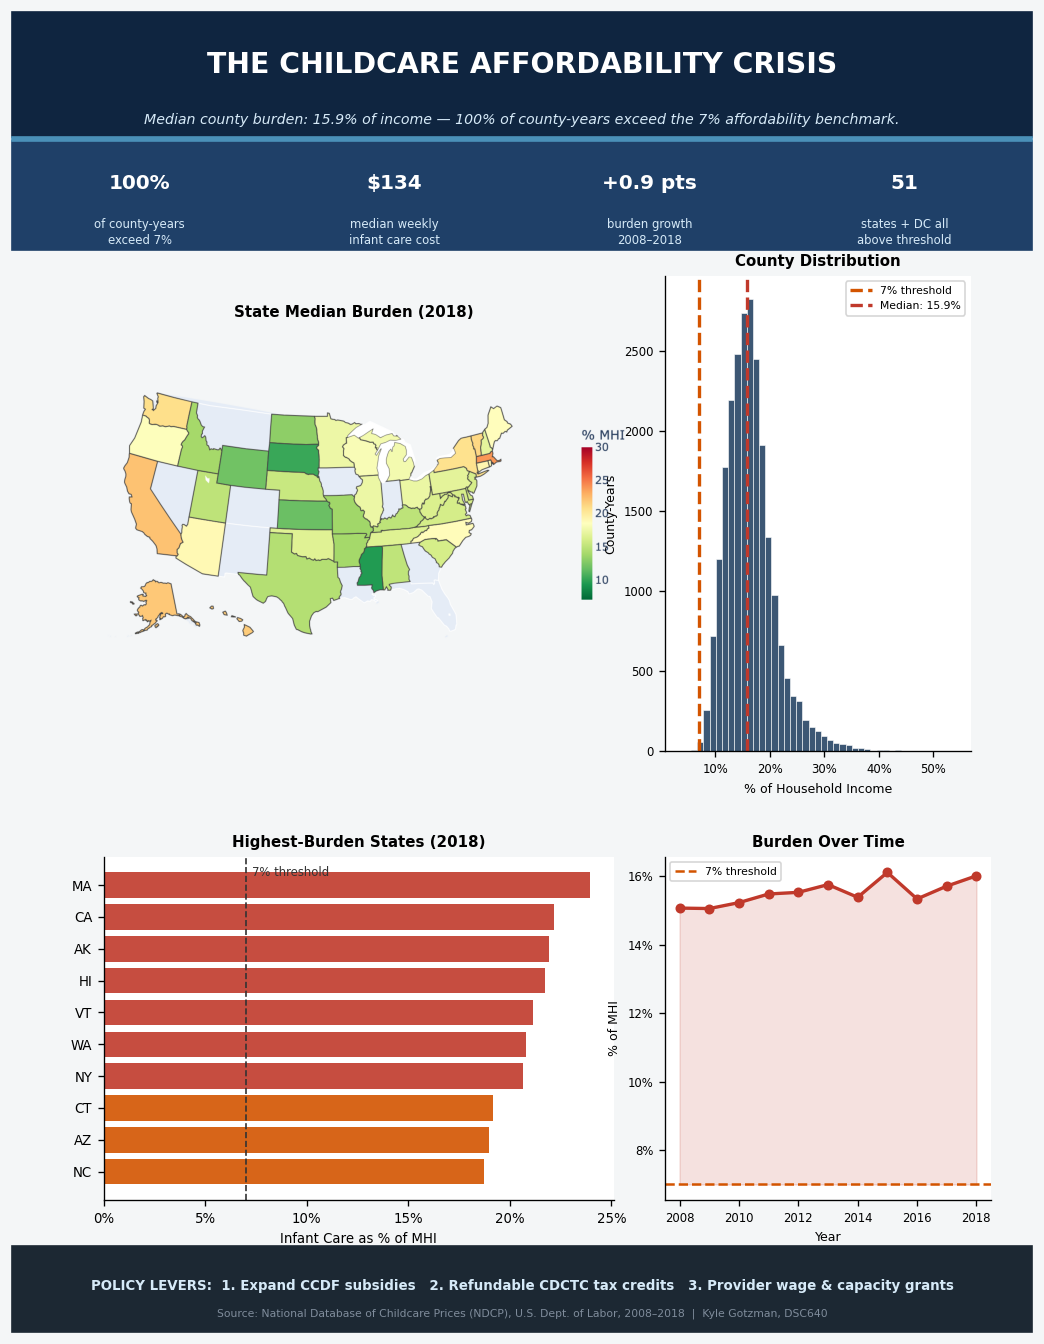

Medium 1 complete — static infographic rendered.


In [3]:
# ======================================================================
# MEDIUM 1 - STATIC INFOGRAPHIC
# Unique visuals: choropleth map, histogram, horizontal bar chart, trend line
# ======================================================================

map_img = plotly_state_map(state_df, f'State Median Burden ({latest_year})')

fig = plt.figure(figsize=(8.5, 11), facecolor=CREAM)

for y0, h, c in [(0.905, 0.095, NAVY), (0.820, 0.082, '#1f4068'), (0.0, 0.065, DARK)]:
    fig.patches.append(Rectangle((0, y0), 1, h, transform=fig.transFigure, color=c, zorder=0))
fig.patches.append(Rectangle((0, 0.902), 1, 0.003, transform=fig.transFigure, color='#4a90b8', zorder=1))

fig.text(0.5, 0.960, 'THE CHILDCARE AFFORDABILITY CRISIS',
         ha='center', va='center', fontsize=17, fontweight='bold', color=WHITE, zorder=2)
fig.text(
    0.5, 0.918,
    f'Median county burden: {median_ratio:.1f}% of income'
    f' \u2014 {above_pct:.0f}% of county-years exceed the 7% affordability benchmark.',
    ha='center', va='center', fontsize=8.5, color=LIGHT_B, style='italic', zorder=2,
)

callouts = [
    (f'{above_pct:.0f}%', 'of county-years\nexceed 7%'),
    (f'${monthly_median:,.0f}', 'median weekly\ninfant care cost'),
    (f'+{yearly["ratio"].iloc[-1] - yearly["ratio"].iloc[0]:.1f} pts', 'burden growth\n2008\u20132018'),
    ('51', 'states + DC all\nabove threshold'),
]
for i, (stat, label) in enumerate(callouts):
    cx = (i + 0.5) / len(callouts)
    fig.text(cx, 0.870, stat, ha='center', va='center', fontsize=12, fontweight='bold', color=WHITE, zorder=2)
    fig.text(cx, 0.833, label, ha='center', va='center', fontsize=7, color=LIGHT_B, linespacing=1.35, zorder=2)

ax_map = fig.add_axes([0.06, 0.44, 0.55, 0.36])
ax_map.imshow(map_img)
ax_map.axis('off')
ax_map.set_title(f'State Median Burden ({latest_year})', fontsize=9, fontweight='bold', pad=4)

ax_hist = fig.add_axes([0.64, 0.44, 0.30, 0.36])
ax_hist.hist(ratio_all, bins=45, color=STEEL, edgecolor='white', alpha=0.85, linewidth=0.4)
ax_hist.axvline(7, color=ORANGE, linestyle='--', linewidth=2, label='7% threshold')
ax_hist.axvline(median_ratio, color=TOMATO, linestyle='--', linewidth=2, label=f'Median: {median_ratio:.1f}%')
ax_hist.set_title('County Distribution', fontsize=9, fontweight='bold')
ax_hist.set_xlabel('% of Household Income', fontsize=7.5)
ax_hist.set_ylabel('County-Years', fontsize=7.5)
ax_hist.xaxis.set_major_formatter(mticker.PercentFormatter(100, 0))
ax_hist.tick_params(labelsize=7)
ax_hist.legend(fontsize=6.5, loc='upper right')

ax_bar = fig.add_axes([0.09, 0.10, 0.50, 0.26])
top10 = state_df.head(10)
bar_colors = [TOMATO if v > 20 else ORANGE for v in top10['infant_pct_mhi']]
ax_bar.barh(top10['State_Abbreviation'][::-1], top10['infant_pct_mhi'][::-1], color=bar_colors[::-1], alpha=0.9)
ax_bar.axvline(7, color='#333', linestyle='--', linewidth=1)
ax_bar.text(7.3, 9.6, '7% threshold', fontsize=7, color='#333', va='top')
ax_bar.set_title(f'Highest-Burden States ({latest_year})', fontsize=9, fontweight='bold')
ax_bar.set_xlabel('Infant Care as % of MHI', fontsize=8)
ax_bar.xaxis.set_major_formatter(mticker.PercentFormatter(100, 0))
ax_bar.tick_params(labelsize=8)

ax_trend = fig.add_axes([0.64, 0.10, 0.32, 0.26])
ax_trend.plot(yearly['StudyYear'], yearly['ratio'], marker='o', color=TOMATO, linewidth=2, markersize=5)
ax_trend.axhline(7, color=ORANGE, linestyle='--', linewidth=1.5, label='7% threshold')
ax_trend.fill_between(yearly['StudyYear'], 7, yearly['ratio'], alpha=0.15, color=TOMATO)
ax_trend.set_title('Burden Over Time', fontsize=9, fontweight='bold')
ax_trend.set_xlabel('Year', fontsize=7.5)
ax_trend.set_ylabel('% of MHI', fontsize=7.5)
ax_trend.yaxis.set_major_formatter(mticker.PercentFormatter(100, 0))
ax_trend.tick_params(labelsize=7)
ax_trend.legend(fontsize=6.5)

fig.text(0.5, 0.032, 'POLICY LEVERS:  1. Expand CCDF subsidies   2. Refundable CDCTC tax credits   3. Provider wage & capacity grants',
         ha='center', fontsize=8, color=LIGHT_B, fontweight='bold', zorder=2)
fig.text(0.5, 0.012, 'Source: National Database of Childcare Prices (NDCP), U.S. Dept. of Labor, 2008\u20132018  |  Kyle Gotzman, DSC640',
         ha='center', fontsize=6.5, color='#7f8c9b', zorder=2)

plt.show()
print('Medium 1 complete \u2014 static infographic rendered.')

---
## Medium 2: Interactive Web Dashboard

### Design Narrative

The dashboard is built entirely in Plotly and uses a distinct set of visual types not found in the infographic or slide deck:

- **Sunburst chart** (top-left): A hierarchical ring showing Census Region to State, sized by the number of counties and colored by median affordability burden. This replaces the choropleth map used in Medium 1 and gives the audience a region-first drill-down that a flat map cannot.
- **Filled area chart** (top-right): National median burden over 2008-2018 with the gap above the 7% threshold shaded in red. This differs from the simple trend line in Medium 1 by emphasizing the cumulative excess above the policy benchmark.
- **Grouped bar chart** (bottom-left): Compares center-based vs. family home care costs across age groups for the latest year, revealing that the affordability problem is not limited to one care type. No bar chart of this form appears in the infographic.
- **Summary table** (bottom-right): Top 15 highest-burden states with numeric detail. Tables appear in no other medium.

The background and light gray grid lines separate panels without visual noise. The consistent RdYlGn_r palette on the sunburst ties color meaning back to the infographic without duplicating the chart type.

In [4]:
# ======================================================================
# MEDIUM 2 - INTERACTIVE DASHBOARD
# Unique visuals: sunburst chart, filled area chart, grouped bar chart, table
# ======================================================================

state_latest = state_df.copy()
county_counts = (
    df[df['StudyYear'] == latest_year]
    .groupby('State_Abbreviation')['County_Name']
    .nunique()
    .reset_index()
    .rename(columns={'County_Name': 'n_counties'})
)
state_latest = state_latest.merge(county_counts, on='State_Abbreviation', how='left')

sb_labels = ['US'] + list(CENSUS_REGIONS.keys()) + list(state_latest['State_Abbreviation'])
sb_parents = [''] + ['US'] * len(CENSUS_REGIONS)
sb_values = [0] + [0] * len(CENSUS_REGIONS)
sb_colors = [median_ratio] + [
    state_latest[state_latest['region'] == r]['infant_pct_mhi'].median()
    for r in CENSUS_REGIONS
]

for _, row in state_latest.iterrows():
    sb_parents.append(row['region'])
    sb_values.append(int(row.get('n_counties', 1)))
    sb_colors.append(row['infant_pct_mhi'])

care_cols = {
    'MCInfant': 'Center Infant',
    'MCToddler': 'Center Toddler',
    'MCPreschool': 'Center Preschool',
    'MFCCInfant': 'Family Infant',
    'MFCCToddler': 'Family Toddler',
    'MFCCPreschool': 'Family Preschool',
}
care_latest = df[df['StudyYear'] == latest_year][list(care_cols.keys())].median()
care_annual = care_latest * 52
center_vals = [care_annual['MCInfant'], care_annual['MCToddler'], care_annual['MCPreschool']]
family_vals = [care_annual['MFCCInfant'], care_annual['MFCCToddler'], care_annual['MFCCPreschool']]
age_groups = ['Infant', 'Toddler', 'Preschool']

top15 = state_df.head(15).copy()
top15['infant_pct_mhi'] = top15['infant_pct_mhi'].round(1)

dashboard = make_subplots(
    rows=2, cols=2,
    row_heights=[0.55, 0.45],
    specs=[
        [{'type': 'sunburst'}, {'type': 'xy'}],
        [{'type': 'xy'}, {'type': 'table'}],
    ],
    subplot_titles=[
        'Burden by Region & State (County-Weighted)',
        f'National Affordability Trend ({int(yearly["StudyYear"].min())}\u2013{latest_year})',
        f'Annual Cost by Care Type ({latest_year})',
        f'Top 15 Highest-Burden States ({latest_year})',
    ],
    horizontal_spacing=0.10,
    vertical_spacing=0.13,
)

dashboard.add_trace(
    go.Sunburst(
        labels=sb_labels,
        parents=sb_parents,
        values=sb_values,
        marker=dict(
            colors=sb_colors,
            colorscale='RdYlGn_r',
            cmin=7, cmax=30,
            colorbar=dict(title='% MHI', thickness=12, len=0.4, x=0.45, y=0.78),
        ),
        branchvalues='total',
        hovertemplate='<b>%{label}</b><br>Burden: %{color:.1f}%<br>Counties: %{value}<extra></extra>',
    ),
    row=1, col=1,
)

dashboard.add_trace(
    go.Scatter(
        x=yearly['StudyYear'], y=yearly['ratio'],
        mode='lines+markers',
        name='National Median',
        line=dict(color=TOMATO, width=3),
        marker=dict(size=7),
        fill='tozeroy',
        fillcolor='rgba(192, 57, 43, 0.15)',
    ),
    row=1, col=2,
)
dashboard.add_trace(
    go.Scatter(
        x=[yearly['StudyYear'].min(), yearly['StudyYear'].max()],
        y=[7, 7],
        mode='lines',
        name='7% threshold',
        line=dict(color=GOLD, width=2, dash='dash'),
        showlegend=False,
    ),
    row=1, col=2,
)

dashboard.add_trace(
    go.Bar(
        x=age_groups, y=center_vals,
        name='Center-Based',
        marker_color=TOMATO,
        text=[f'${v:,.0f}' for v in center_vals],
        textposition='outside',
    ),
    row=2, col=1,
)
dashboard.add_trace(
    go.Bar(
        x=age_groups, y=family_vals,
        name='Family Home',
        marker_color=ACCENT,
        text=[f'${v:,.0f}' for v in family_vals],
        textposition='outside',
    ),
    row=2, col=1,
)

dashboard.add_trace(
    go.Table(
        header=dict(
            values=['Rank', 'State', 'Burden (% MHI)'],
            fill_color=NAVY,
            font=dict(color=WHITE, size=12),
            align='center',
        ),
        cells=dict(
            values=[
                list(range(1, len(top15) + 1)),
                top15['State_Abbreviation'].tolist(),
                [f'{v:.1f}%' for v in top15['infant_pct_mhi']],
            ],
            fill_color=[CREAM, CREAM, [
                '#fde8e8' if v > 20 else '#fef3e2' if v > 15 else CREAM
                for v in top15['infant_pct_mhi']
            ]],
            font=dict(size=11),
            align='center',
        ),
    ),
    row=2, col=2,
)

dashboard.update_layout(
    height=850,
    width=1100,
    title_text='Childcare Affordability Dashboard \u2014 NDCP Data',
    title_font_size=18,
    paper_bgcolor=BG,
    plot_bgcolor=BG,
    barmode='group',
    showlegend=True,
    legend=dict(x=0.01, y=0.42, bgcolor='rgba(255,255,255,0.7)'),
)
dashboard.update_yaxes(title_text='% of MHI', row=1, col=2)
dashboard.update_yaxes(title_text='Annual Cost ($)', row=2, col=1)

dashboard.show()
print('Medium 2 complete \u2014 interactive dashboard rendered.')

Medium 2 complete — interactive dashboard rendered.


---
## Medium 3: Slide Deck (Presentation / Committee Testimony)

### Design Narrative

Each slide uses a widescreen 16:9 canvas (12x6.75 in) with a consistent dark background so projected charts maintain contrast in committee rooms. This medium uses four visual types that appear nowhere else in the project:

- **Box plot** (Slide 2): Shows the distribution of county-level burden within each Census region, revealing both median and spread. Unlike the infographic's histogram (which aggregates nationally) or bar chart (which shows point estimates), the box plot exposes regional inequality in a single frame.
- **Lollipop chart** (Slide 3): Ranks all states by burden with dot-and-stem encoding. This is visually distinct from the infographic's horizontal bars and highlights the full state ranking rather than just the top 10.
- **Indexed growth dual-panel** (Slide 4): Rebases childcare costs and MHI to 2008=100 so the audience sees relative growth rates side by side. This differs from the infographic's raw-value trend line and the dashboard's filled area chart.
- **Scatter plot** (Slide 5): Burden vs. female labor force participation with year-colored points. This visual type does not appear in any other medium.

Font sizes are bumped 30-50% above infographic equivalents for rear-projection legibility. Slide headers use a colored band (tomato for evidence slides, accent blue for bookends) to signal narrative phase.

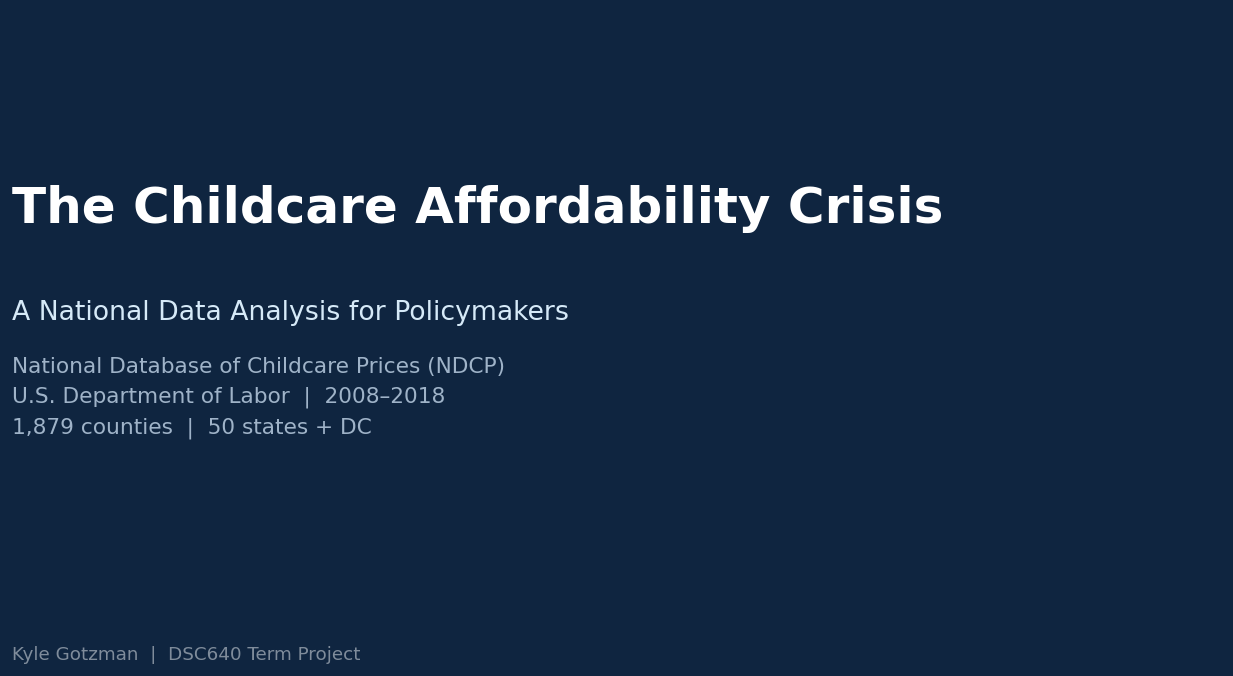

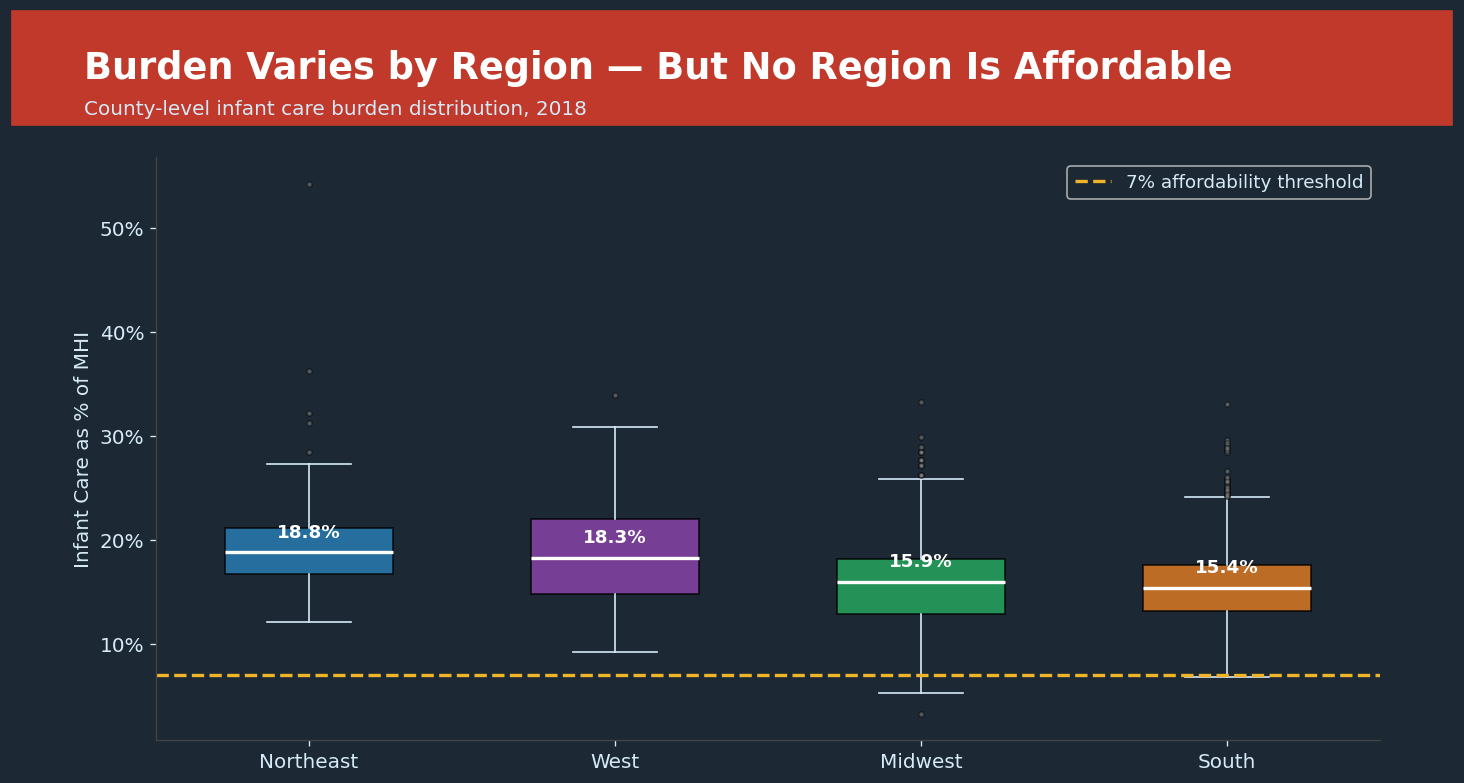

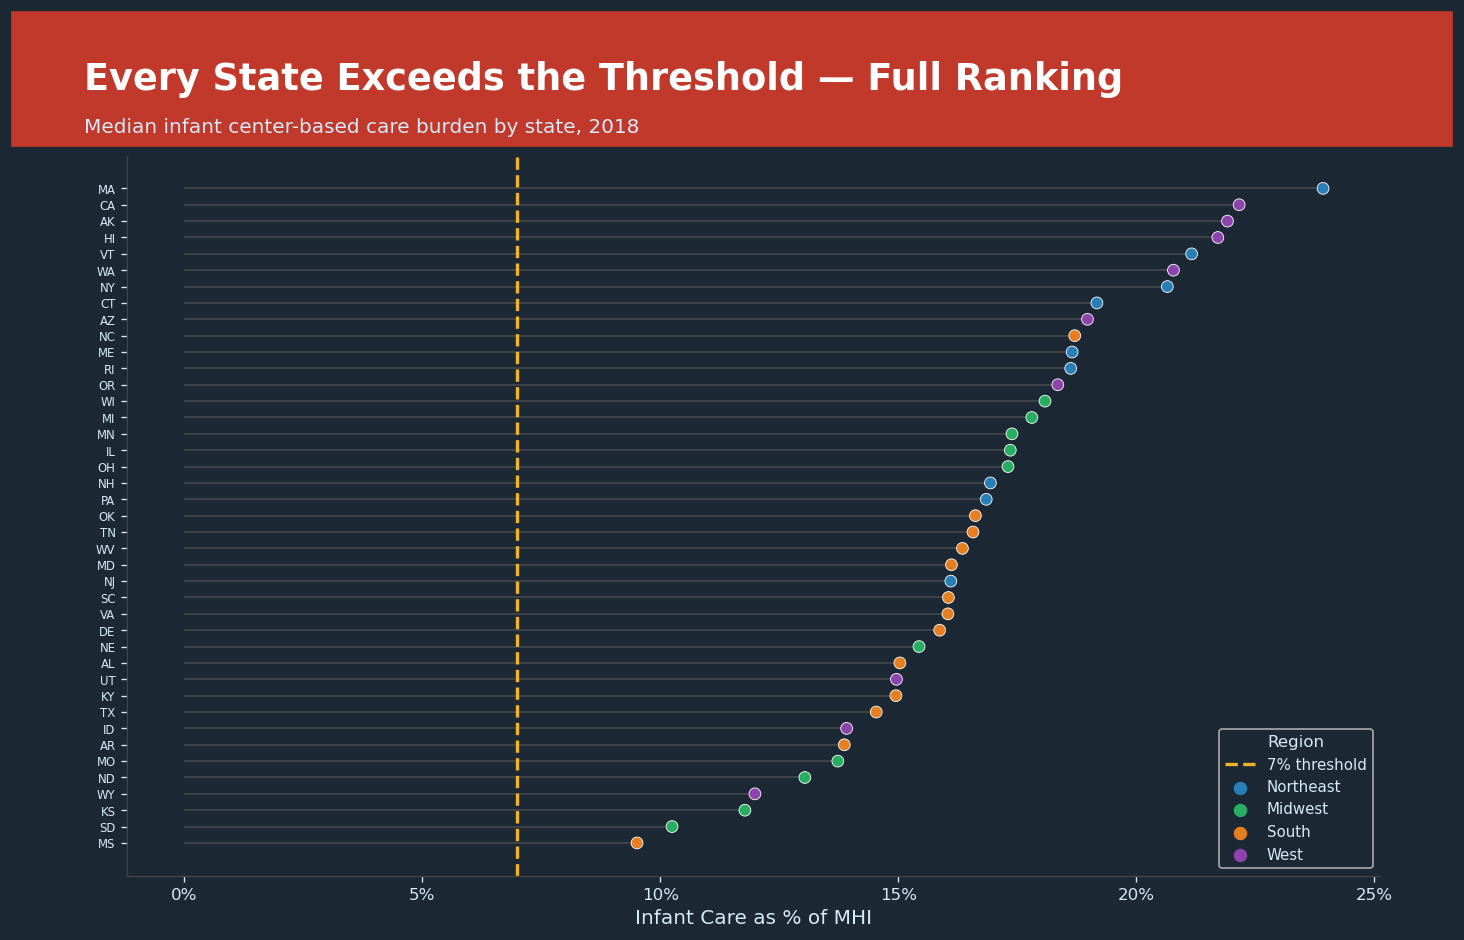

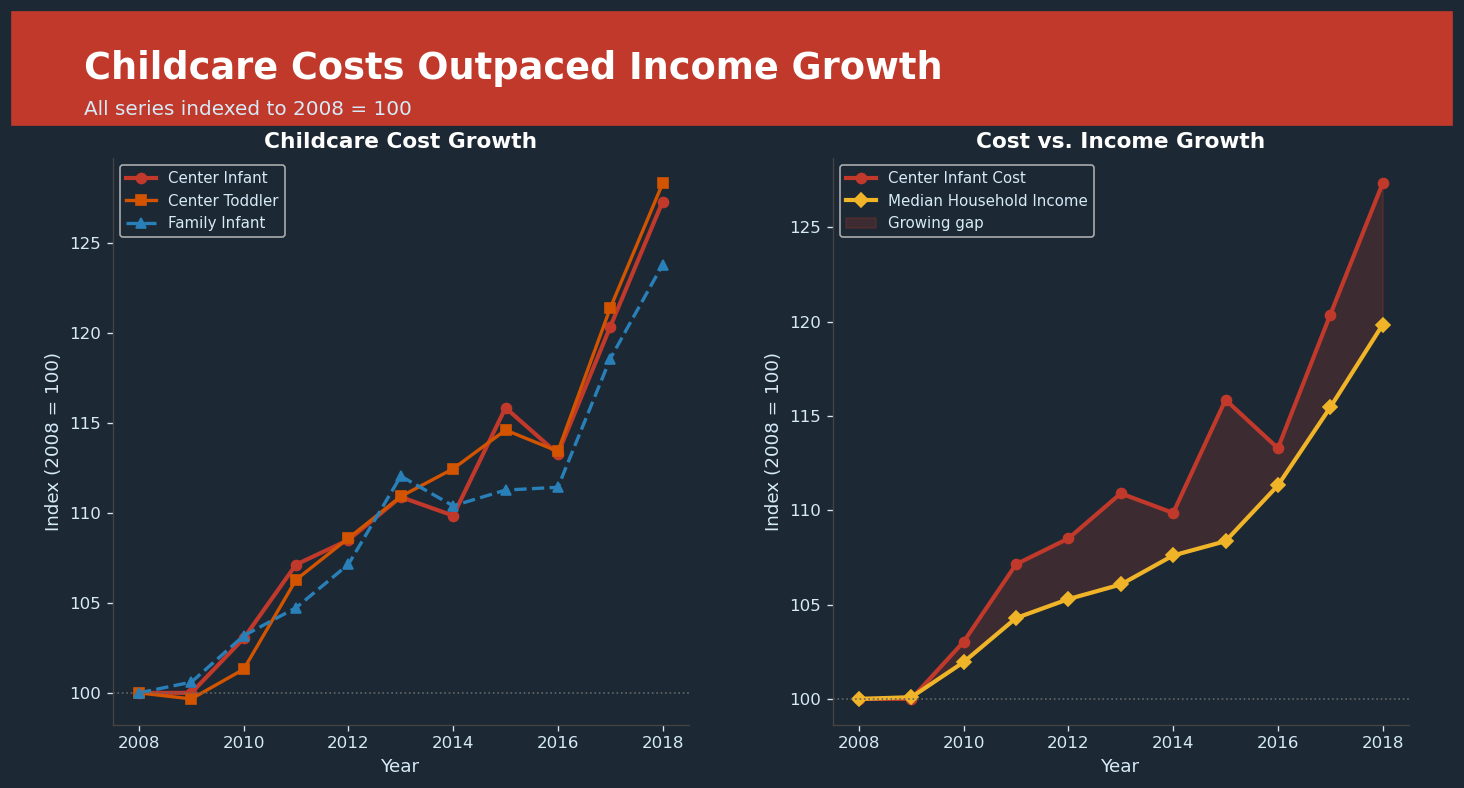

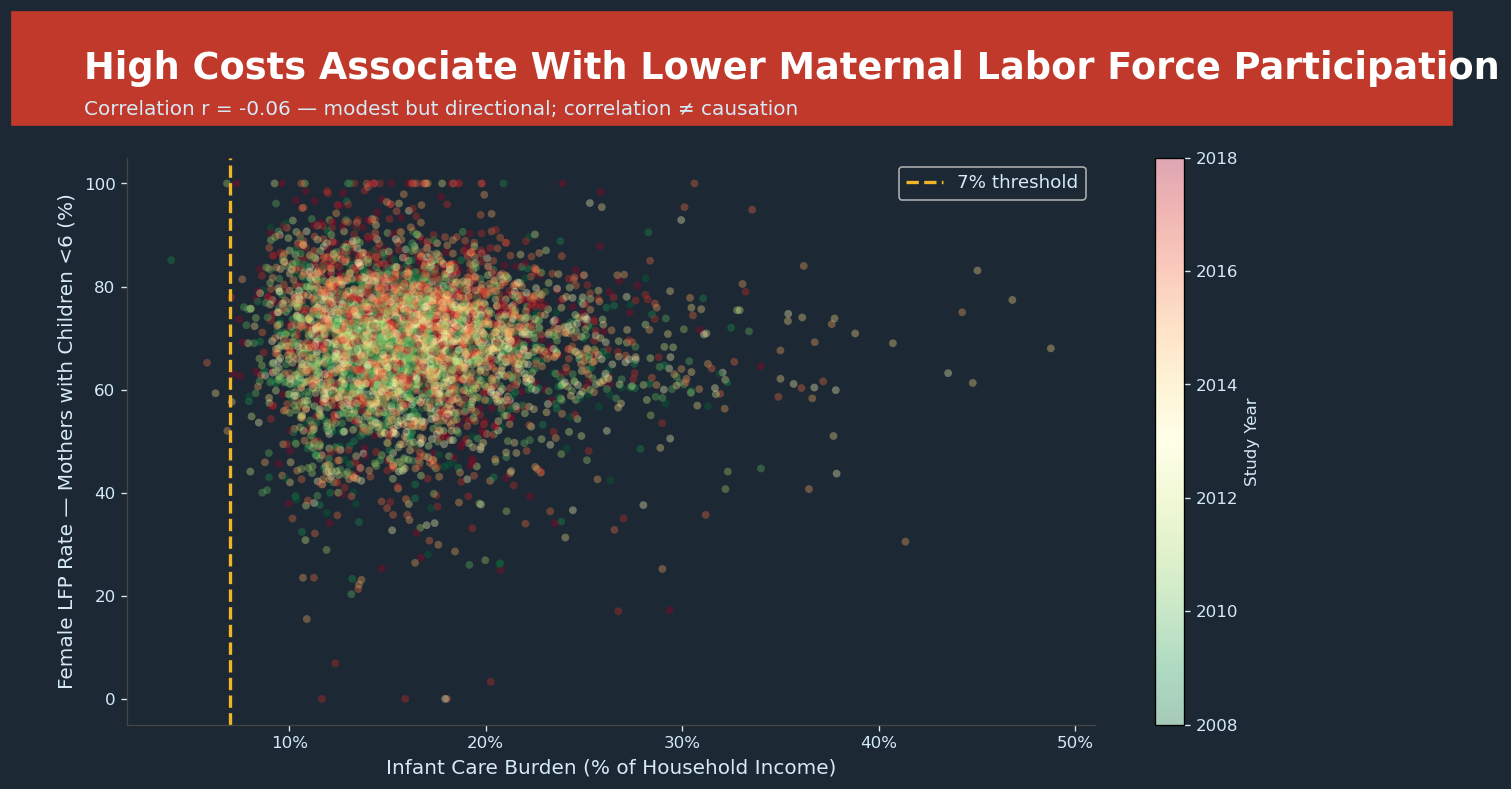

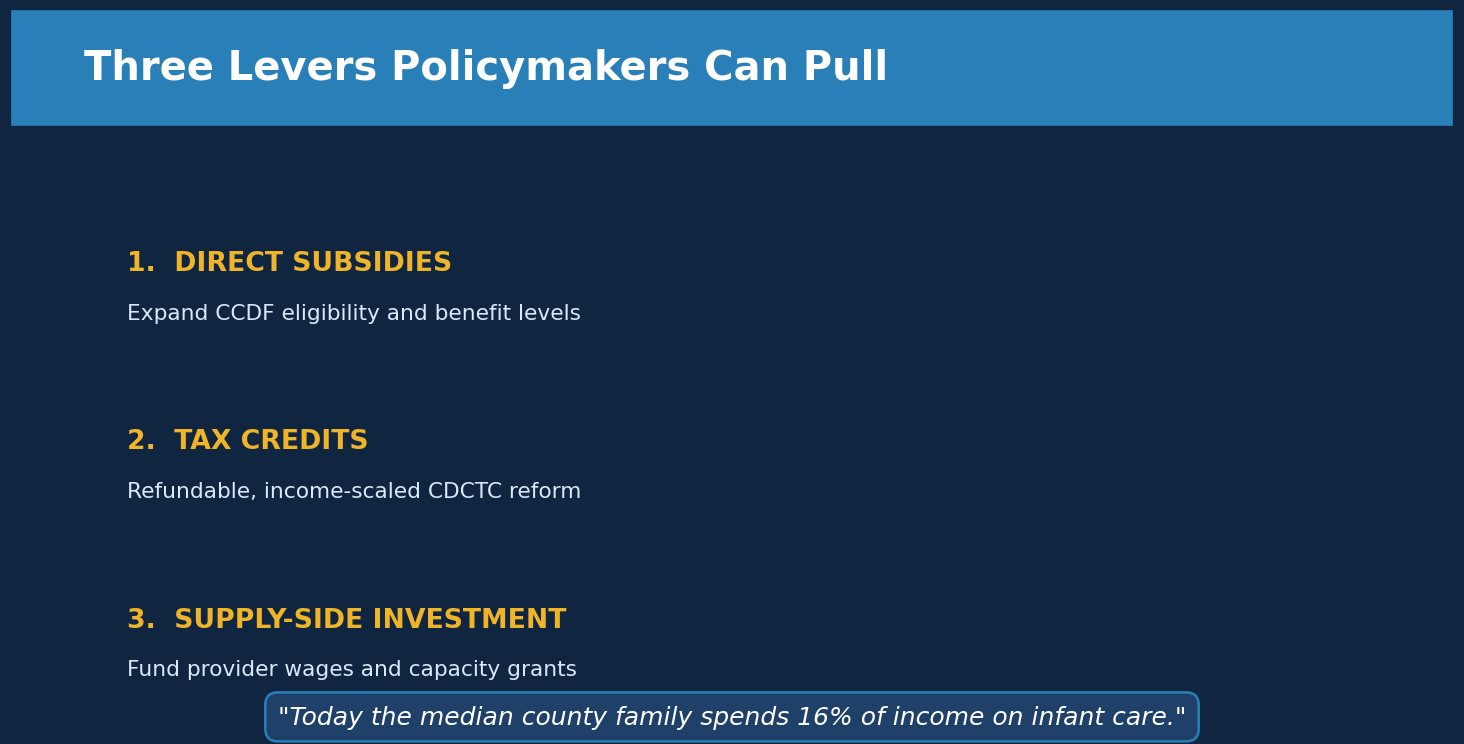

Medium 3 complete — 6 slides rendered.


In [5]:
# ======================================================================
# MEDIUM 3 - SLIDE DECK
# Unique visuals: box plot, lollipop chart, indexed growth dual-panel, scatter
# ======================================================================

SLIDE_SIZE = (12, 6.75)

def style_slide_axes(ax, dark=True):
    if dark:
        ax.set_facecolor(DARK)
        for spine in ax.spines.values():
            spine.set_color('#444')
        ax.tick_params(colors=LIGHT_B)
        ax.xaxis.label.set_color(LIGHT_B)
        ax.yaxis.label.set_color(LIGHT_B)
    return ax

def add_slide_header(fig, title, subtitle=None, band_color=TOMATO):
    fig.patches.append(Rectangle((0, 0.86), 1, 0.14, transform=fig.transFigure, color=band_color, zorder=0))
    fig.text(0.05, 0.93, title, fontsize=22, fontweight='bold', color=WHITE, va='center')
    if subtitle:
        fig.text(0.05, 0.88, subtitle, fontsize=12, color=LIGHT_B, va='center')

# Slide 1: Title
fig1, ax1 = plt.subplots(figsize=SLIDE_SIZE, facecolor=NAVY)
ax1.set_facecolor(NAVY)
ax1.axis('off')
fig1.text(0.06, 0.62, 'The Childcare Affordability Crisis', fontsize=30, fontweight='bold', color=WHITE)
fig1.text(0.06, 0.50, 'A National Data Analysis for Policymakers', fontsize=16, color=LIGHT_B)
fig1.text(0.06, 0.36,
          'National Database of Childcare Prices (NDCP)\n'
          'U.S. Department of Labor  |  2008\u20132018\n'
          f'{df["County_Name"].nunique():,} counties  |  50 states + DC',
          fontsize=13, color='#9fb3c8', linespacing=1.6)
fig1.text(0.06, 0.08, 'Kyle Gotzman  |  DSC640 Term Project', fontsize=11, color='#7f8c9b')
plt.show()

# Slide 2: Regional Box Plot
fig2, ax2 = plt.subplots(figsize=SLIDE_SIZE, facecolor=DARK)
style_slide_axes(ax2)
add_slide_header(fig2, 'Burden Varies by Region \u2014 But No Region Is Affordable',
                 f'County-level infant care burden distribution, {latest_year}')

region_order = ['Northeast', 'West', 'Midwest', 'South']
box_data = []
box_colors = []
for r in region_order:
    vals = df[(df['StudyYear'] == latest_year) & (df['region'] == r)]['infant_pct_mhi'].dropna()
    box_data.append(vals)
    box_colors.append(REGION_COLORS[r])

bp = ax2.boxplot(box_data, labels=region_order, patch_artist=True, widths=0.55,
                 medianprops=dict(color=WHITE, linewidth=2),
                 whiskerprops=dict(color=LIGHT_B),
                 capprops=dict(color=LIGHT_B),
                 flierprops=dict(marker='o', markerfacecolor='#aaa', markersize=3, alpha=0.4))
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)

ax2.axhline(7, color=GOLD, linestyle='--', linewidth=2, label='7% affordability threshold')
ax2.set_ylabel('Infant Care as % of MHI', fontsize=12)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(100, 0))
ax2.legend(fontsize=11, facecolor=DARK, labelcolor=LIGHT_B, loc='upper right')
ax2.tick_params(labelsize=12)

for i, r in enumerate(region_order):
    med_val = box_data[i].median()
    ax2.text(i + 1, med_val + 1.5, f'{med_val:.1f}%', ha='center', fontsize=11,
             color=WHITE, fontweight='bold')

plt.subplots_adjust(top=0.82, left=0.10, right=0.95, bottom=0.10)
plt.show()

# Slide 3: Lollipop Chart (State Rankings)
fig3, ax3 = plt.subplots(figsize=(12, 8), facecolor=DARK)
style_slide_axes(ax3)
add_slide_header(fig3, 'Every State Exceeds the Threshold \u2014 Full Ranking',
                 f'Median infant center-based care burden by state, {latest_year}')

ranked = state_df.sort_values('infant_pct_mhi', ascending=True).reset_index(drop=True)
y_pos = range(len(ranked))
dot_colors = [REGION_COLORS.get(ranked.iloc[i]['region'], STEEL) for i in y_pos]

ax3.hlines(y=y_pos, xmin=0, xmax=ranked['infant_pct_mhi'], color='#555', linewidth=1, alpha=0.7)
ax3.scatter(ranked['infant_pct_mhi'], y_pos, c=dot_colors, s=50, zorder=3, edgecolors='white', linewidth=0.5)
ax3.axvline(7, color=GOLD, linestyle='--', linewidth=2, label='7% threshold')
ax3.set_yticks(list(y_pos))
ax3.set_yticklabels(ranked['State_Abbreviation'], fontsize=7)
ax3.set_xlabel('Infant Care as % of MHI', fontsize=12)
ax3.xaxis.set_major_formatter(mticker.PercentFormatter(100, 0))

for r, c in REGION_COLORS.items():
    ax3.scatter([], [], c=c, s=50, label=r)
ax3.legend(fontsize=9, facecolor=DARK, labelcolor=LIGHT_B, loc='lower right', title='Region',
           title_fontsize=10)
ax3.legend_.get_title().set_color(LIGHT_B)

plt.subplots_adjust(top=0.85, left=0.08, right=0.95, bottom=0.10)
plt.show()

# Slide 4: Indexed Growth (Costs vs. Income, 2008=100)
fig4, axes = plt.subplots(1, 2, figsize=SLIDE_SIZE, facecolor=DARK)
for ax in axes:
    style_slide_axes(ax)
fig4.patches.append(Rectangle((0, 0.86), 1, 0.14, transform=fig4.transFigure, color=TOMATO, zorder=0))
fig4.text(0.05, 0.93, 'Childcare Costs Outpaced Income Growth', fontsize=22, fontweight='bold', color=WHITE, va='center')
fig4.text(0.05, 0.88, 'All series indexed to 2008 = 100', fontsize=12, color=LIGHT_B, va='center')

base_cost = yearly['MCInfant'].iloc[0]
base_mhi = yearly['MHI'].iloc[0]

axes[0].plot(yearly['StudyYear'], yearly['MCInfant'] / base_cost * 100,
             marker='o', color=TOMATO, linewidth=2.5, label='Center Infant')
axes[0].plot(yearly['StudyYear'], yearly['MCToddler'] / yearly['MCToddler'].iloc[0] * 100,
             marker='s', color=ORANGE, linewidth=2, label='Center Toddler')
axes[0].plot(yearly['StudyYear'], yearly['MFCCInfant'] / yearly['MFCCInfant'].iloc[0] * 100,
             marker='^', color=ACCENT, linewidth=2, linestyle='--', label='Family Infant')
axes[0].axhline(100, color='#666', linestyle=':', linewidth=1)
axes[0].set_title('Childcare Cost Growth', fontsize=13, fontweight='bold', color=WHITE)
axes[0].set_xlabel('Year', fontsize=11)
axes[0].set_ylabel('Index (2008 = 100)', fontsize=11)
axes[0].legend(fontsize=9, facecolor=DARK, labelcolor=LIGHT_B)

axes[1].plot(yearly['StudyYear'], yearly['MCInfant'] / base_cost * 100,
             marker='o', color=TOMATO, linewidth=2.5, label='Center Infant Cost')
axes[1].plot(yearly['StudyYear'], yearly['MHI'] / base_mhi * 100,
             marker='D', color=GOLD, linewidth=2.5, label='Median Household Income')
axes[1].fill_between(
    yearly['StudyYear'],
    yearly['MHI'] / base_mhi * 100,
    yearly['MCInfant'] / base_cost * 100,
    alpha=0.2, color=TOMATO, label='Growing gap',
)
axes[1].axhline(100, color='#666', linestyle=':', linewidth=1)
axes[1].set_title('Cost vs. Income Growth', fontsize=13, fontweight='bold', color=WHITE)
axes[1].set_xlabel('Year', fontsize=11)
axes[1].set_ylabel('Index (2008 = 100)', fontsize=11)
axes[1].legend(fontsize=9, facecolor=DARK, labelcolor=LIGHT_B)

plt.subplots_adjust(top=0.82, wspace=0.25, left=0.07, right=0.97, bottom=0.12)
plt.show()

# Slide 5: Scatter (Burden vs. Female LFP)
fig5, ax5 = plt.subplots(figsize=SLIDE_SIZE, facecolor=DARK)
style_slide_axes(ax5)
add_slide_header(fig5, 'High Costs Associate With Lower Maternal Labor Force Participation',
                 f'Correlation r = {flfpr_corr:.2f} \u2014 modest but directional; correlation \u2260 causation')
sample = scatter_df.sample(min(5000, len(scatter_df)), random_state=42)
sc = ax5.scatter(sample['infant_pct_mhi'], sample['FLFPR_20to64_Under6'],
                 c=sample['StudyYear'], cmap='RdYlGn_r', alpha=0.35, edgecolors='none', s=22)
cbar = plt.colorbar(sc, ax=ax5)
cbar.set_label('Study Year', color=LIGHT_B)
cbar.ax.yaxis.set_tick_params(color=LIGHT_B)
plt.setp(plt.getp(cbar.ax.axes, 'yticklabels'), color=LIGHT_B)
ax5.axvline(7, color=GOLD, linestyle='--', linewidth=2, label='7% threshold')
ax5.set_xlabel('Infant Care Burden (% of Household Income)', fontsize=12)
ax5.set_ylabel('Female LFP Rate \u2014 Mothers with Children <6 (%)', fontsize=12)
ax5.xaxis.set_major_formatter(mticker.PercentFormatter(100, 0))
ax5.legend(fontsize=11, facecolor=DARK, labelcolor=LIGHT_B)
plt.subplots_adjust(top=0.82, left=0.08, right=0.92, bottom=0.12)
plt.show()

# Slide 6: Call to Action
fig6, ax6 = plt.subplots(figsize=SLIDE_SIZE, facecolor=NAVY)
ax6.set_facecolor(NAVY)
ax6.axis('off')
fig6.patches.append(Rectangle((0, 0.86), 1, 0.14, transform=fig6.transFigure, color=ACCENT, zorder=0))
fig6.text(0.05, 0.93, 'Three Levers Policymakers Can Pull', fontsize=24, fontweight='bold', color=WHITE, va='center')

levers = [
    ('1.  DIRECT SUBSIDIES', 'Expand CCDF eligibility and benefit levels'),
    ('2.  TAX CREDITS', 'Refundable, income-scaled CDCTC reform'),
    ('3.  SUPPLY-SIDE INVESTMENT', 'Fund provider wages and capacity grants'),
]
for i, (title, detail) in enumerate(levers):
    y = 0.68 - i * 0.22
    fig6.text(0.08, y, title, fontsize=16, fontweight='bold', color=GOLD)
    fig6.text(0.08, y - 0.06, detail, fontsize=13, color=LIGHT_B)

fig6.text(0.5, 0.12,
          f'"Today the median county family spends {median_ratio:.0f}% of income on infant care."',
          ha='center', fontsize=15, color=WHITE, style='italic',
          bbox=dict(boxstyle='round,pad=0.5', facecolor='#1f4068', edgecolor=ACCENT, linewidth=1.5))
plt.show()
print('Medium 3 complete \u2014 6 slides rendered.')